# XGBoost probability analysis and a 5,000-text Jev hybrid

This notebook asks whether routing high-error probability ranges to **base Jev** improves upon classical Word2Vec + XGBoost. It first uses **validation data** to identify where XGBoost makes errors. It then compares XGBoost and a Jev-assisted policy on **5,000 label-blind selected test texts**, including texts XGBoost classified correctly.

The new experiment has a separately authorized cap of **5,000 paid inference attempts**. The earlier 100-attempt error-only study and its ledger remain unchanged. Default **Run All reads saved results and makes no paid calls**. This is an inference-time hybrid, not a weight-fine-tuned model.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "jev_research").is_dir() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Start this notebook inside the repository.")
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "research/results/jev_probability_hybrid"
ARTIFACTS = ROOT / "artifacts/jev_probability_hybrid"
RUN_PREPARATION = False
RUN_PAID_INFERENCE = False
NEW_AUTHORIZED_ATTEMPTS = 5000
print("Default mode: saved evidence only, no paid inference.")

Default mode: saved evidence only, no paid inference.


## 1. Define the critical range without test-label selection

XGBoost outputs are class scores in [0,1], classified at 0.50. A high error **count** can reflect a large bin, whereas an error **rate** measures how often a bin is wrong; both are reported. We use 20 prespecified probability bins of width 0.05, with [lower, upper) boundaries and probability 1 included in the last bin. The supported peak requires at least 100 validation texts.

The empirically worst validation bin is too small to provide 5,000 test texts. To define a feasible critical interval, search all 210 contiguous grid-aligned windows, maximizing **validation error rate** subject to a fixed minimum support:

`ceil(1.10 × 5000 × validation_size / test_size)`

The 10% capacity buffer is fixed before Jev outcomes. Ties prefer a narrower interval and then a lower endpoint. Test labels and test error rates are not inputs to this search. If the frozen interval cannot supply 5,000 test texts, preparation fails instead of silently widening it.

In [2]:
if RUN_PREPARATION:
    import os
    from jev_research.probability_hybrid import prepare_probability_hybrid
    csv_path = os.environ.get("SUICIDE_DATA_PATH")
    if not csv_path:
        raise RuntimeError("Set SUICIDE_DATA_PATH to the original CSV.")
    prepare_probability_hybrid(csv_path, ARTIFACTS, RESULTS, ROOT / "artifacts/jev_study")

study = json.loads((RESULTS / "study.json").read_text())
bins = pd.read_json(RESULTS / "validation_bins.json")
selection = study["interval_selection"]
print("Highest supported validation error-rate bin:", selection["highest_error_rate_bin"])
print("Highest validation error-count bin:", selection["highest_error_count_bin"])
print("Minimum validation support:", selection["minimum_validation_support"])
print("Frozen feasible interval:", study["interval"])
print("Selected interval on validation:", selection["selected_validation"])
display(bins[["lower", "upper", "n", "errors", "error_rate"]])

Highest supported validation error-rate bin: {'error_rate': 0.5141388174807198, 'errors': 200, 'lower': 0.45, 'n': 389, 'upper': 0.5, 'upper_inclusive': False, 'wilson_95': [0.46457661125147026, 0.5634245066372117]}
Highest validation error-count bin: {'error_rate': 0.5141388174807198, 'errors': 200, 'lower': 0.45, 'n': 389, 'upper': 0.5, 'upper_inclusive': False, 'wilson_95': [0.46457661125147026, 0.5634245066372117]}
Minimum validation support: 4402
Frozen feasible interval: {'baseline_fingerprint': 'b154407429c3f6d7dd39f87006eb4dd9305d283146ccf27546d57f0d27fa7fd2', 'dataset_sha256': '1ec16b065a2fae36488de16e8abfc326586a576a25901e09467223e545ddd295', 'lower': 0.25, 'target_size': 5000, 'test_population_size': 46342, 'upper': 0.8, 'upper_inclusive': False}
Selected interval on validation: {'error_rate': 0.3390248919975314, 'errors': 1648, 'lower': 0.25, 'n': 4861, 'upper': 0.8, 'upper_inclusive': False, 'wilson_95': [0.3258492389365786, 0.35245476886157523]}


,lower,upper,n,errors,error_rate
0,0.00,0.05,11383,111,0.009751
1,0.05,0.10,2368,127,0.053632
2,0.10,0.15,1176,115,0.097789
3,0.15,0.20,820,131,0.159756
4,0.20,0.25,627,153,0.244019
5,0.25,0.30,516,142,0.275194
6,0.30,0.35,432,131,0.303241
7,0.35,0.40,391,130,0.332481
8,0.40,0.45,347,145,0.417867
9,0.45,0.50,389,200,0.514139


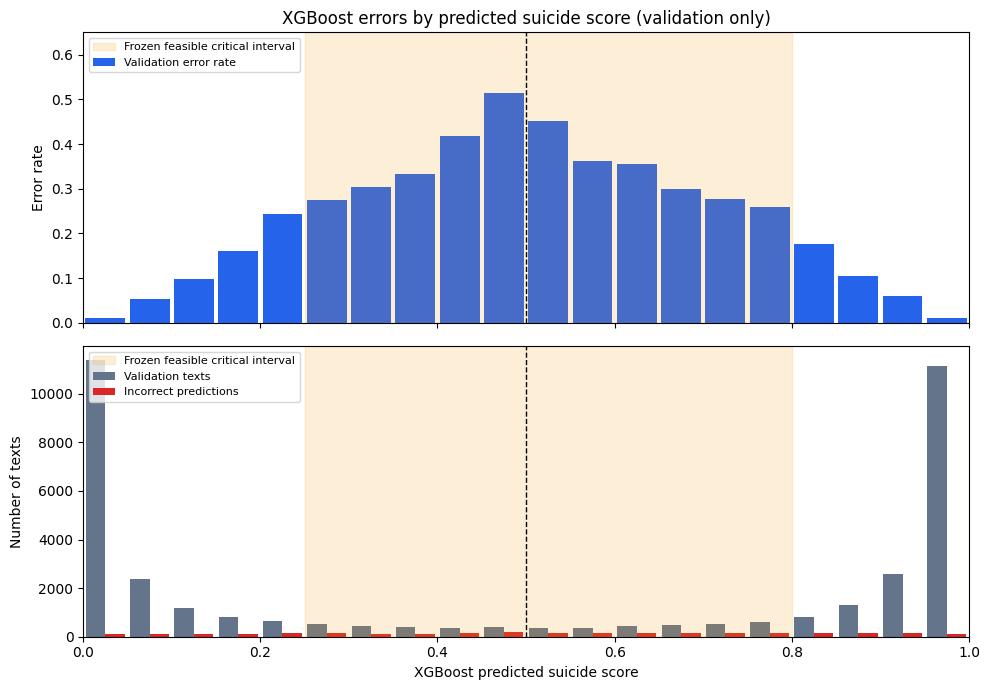

In [3]:
lower, upper = study["interval"]["lower"], study["interval"]["upper"]
midpoint = (bins.lower + bins.upper) / 2
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].bar(midpoint, bins.error_rate, width=0.045, color="#2563eb", label="Validation error rate")
axes[0].set(ylabel="Error rate", ylim=(0, 0.65), title="XGBoost errors by predicted suicide score (validation only)")
axes[1].bar(midpoint - 0.011, bins.n, width=0.022, color="#64748b", label="Validation texts")
axes[1].bar(midpoint + 0.011, bins.errors, width=0.022, color="#dc2626", label="Incorrect predictions")
axes[1].set(xlabel="XGBoost predicted suicide score", ylabel="Number of texts", xlim=(0, 1))
for ax in axes:
    ax.axvspan(lower, upper, color="#f59e0b", alpha=0.16, label="Frozen feasible critical interval")
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
    ax.legend(fontsize=8)
fig.tight_layout()
(ARTIFACTS / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "figures/validation_probability_errors.png", dpi=180)
plt.show()
plt.close(fig)

## 2. Freeze 5,000 texts using scores, not gold correctness

Every test text whose XGBoost score lies in the frozen interval is eligible. A deterministic seed-42 hash ranking chooses exactly 5,000 unique texts. Neither class labels nor XGBoost correctness influence eligibility or ranking. Both correct and incorrect cases therefore enter the experiment, so Jev can introduce errors as well as correct them.

The narrow peak [0.45,0.50) contains only 463 eligible test texts. The validation-selected feasible interval [0.25,0.80) contains 6,067; 5,000 are queried and 1,067 remain with XGBoost. These counts describe score eligibility, not a test-label-based range adjustment.

In [4]:
manifest = pd.read_json(RESULTS / "routing_manifest.json")
assert len(manifest) == 5000 and manifest.sample_id.nunique() == 5000
assert manifest.text_sha256.nunique() == 5000
assert manifest.source_split.eq("test").all()
assert manifest.p_xgb.ge(lower).all() and manifest.p_xgb.lt(upper).all()
assert not {"text", "cleaned_text"}.intersection(manifest.columns)
assert study["cohort_selection"]["test_labels_used_for_selection"] is False
print("Cohort locked at (UTC):", study["cohort_locked_at_utc"])
print("Eligible test texts:", study["cohort_selection"]["eligible_test_count"])
print("Selected for Jev:", len(manifest))
print("Eligible but unqueried:", study["cohort_selection"]["unqueried_interval_count"])
# Descriptive audit after selection; these counts are never sampling inputs.
display(manifest.error_type.value_counts().rename("Selected texts").to_frame())

Cohort locked at (UTC): 2026-10-21T19:05:32.500030+00:00
Eligible test texts: 6067
Selected for Jev: 5000
Eligible but unqueried: 1067


,Selected texts
error_type,
correct,3187
false_positive,953
false_negative,860


## 3. Run the budget-limited hybrid

For the selected texts, a successful Jev score replaces the XGBoost score; predictions use the same fixed 0.50 threshold. Failed, interrupted, or unattempted queries fall back to XGBoost. Every other test text, including the 1,067 unqueried critical-range texts, also keeps XGBoost.

A private SQLite ledger reserves attempts before network I/O and enforces the separate 5,000-attempt/5,000-sample cap. Failures and uncertain interruptions count; no automatic retry or redirect occurs. Exact successes are cached. The runner uses four bounded workers with independent HTTP sessions and stops dispatch after a provider error. Preserve the ledger across resumptions. Set `METIS_API_KEY` securely. Provider JSON payloads omit gold labels and XGBoost scores. Authentication is sent in the Authorization header; credentials are never published in artifacts or notebook output.

Enable the flag only for deliberate paid execution. Default Run All performs no network inference.

In [5]:
if RUN_PAID_INFERENCE:
    from jev_research.probability_hybrid import run_probability_hybrid
    run_probability_hybrid(ARTIFACTS, RESULTS, authorized_attempts=NEW_AUTHORIZED_ATTEMPTS, workers=4)

budget = json.loads((RESULTS / "inference_budget.json").read_text())
assert budget["max_attempts"] == 5000
assert budget["attempts_spent"] <= 5000 and budget["unique_samples_attempted"] <= 5000
print({key: budget[key] for key in ["attempts_spent", "succeeded", "failed", "pending_uncertain", "remaining_attempts"]})
report = json.loads((RESULTS / "hybrid_report.json").read_text())
print("Actual routed coverage:", report["coverage_status"])
print("Successful Jev responses:", report["routing"]["jev_success_n"])
display(Markdown((RESULTS / "hybrid_report.md").read_text()))

audit = json.loads((RESULTS / "execution_audit.json").read_text())
assert audit["attempts_spent"] == audit["distinct_texts_attempted"] == 5000
assert audit["failed_requests_resent"] == 0
print("Counted HTTP 503 fallbacks:", audit["provider_http503_failures"])
print("Recorded attempts were unique; no failed request was resent.")

{'attempts_spent': 5000, 'succeeded': 4996, 'failed': 4, 'pending_uncertain': 0, 'remaining_attempts': 0}
Actual routed coverage: partial_jev_coverage_with_xgboost_fallback
Successful Jev responses: 4996


# Probability-routed Jev hybrid versus XGBoost

Selected test cases: 5000; successful Jev responses: 4996; selected XGBoost fallbacks: 4.

Both models use threshold 0.50. Every selected case remains in the primary comparison, including failed or missing requests.

## Primary: identical selected test cases

Population n=5000.

| Metric | XGBoost | Hybrid |
| --- | ---: | ---: |
| Accuracy | 63.74% | 78.38% |
| Balanced accuracy | 63.28% | 79.26% |
| Positive precision | 66.16% | 88.40% |
| Positive recall | 68.42% | 69.41% |
| Specificity | 58.15% | 89.11% |
| Positive F1 | 0.672685 | 0.777618 |
| Macro F1 | 0.633137 | 0.783633 |
| ROC-AUC | 0.684172 | 0.889443 |
| Average precision | 0.709576 | 0.889352 |
| Brier score | 0.223236 | 0.164997 |
| Log loss | 0.637583 | 0.672543 |

Corrected XGBoost errors: 1339; newly introduced errors: 607; net additional correct cases: 732; accuracy change: +14.64%.
Two-sided exact McNemar p-value: 3.67801e-63.

Corrections must be considered alongside newly introduced errors within each class:

| Error class | XGBoost errors | Corrected | Newly introduced | Hybrid errors | Net reduction |
| --- | ---: | ---: | ---: | ---: | ---: |
| Missed suicide cases (FN) | 860 | 538 | 511 | 833 | +27 |
| False alarms (FP) | 953 | 801 | 96 | 248 | +705 |

| Error outcome | Count / eligible | Rate | 95% Wilson interval |
| --- | ---: | ---: | --- |
| Missed-suicide recovery | 538/860 | 62.56% | 59.27%–65.73% |
| False-alarm correction | 801/953 | 84.05% | 81.59%–86.24% |
| Regression among XGBoost-correct cases | 607/3187 | 19.05% | 17.72%–20.45% |

## Full test: partial routing of the exact selected manifest

Population n=46342.

| Metric | XGBoost | Hybrid |
| --- | ---: | ---: |
| Accuracy | 91.97% | 93.55% |
| Balanced accuracy | 91.97% | 93.55% |
| Positive precision | 91.88% | 94.76% |
| Positive recall | 92.09% | 92.21% |
| Specificity | 91.85% | 94.89% |
| Positive F1 | 0.919864 | 0.934671 |
| Macro F1 | 0.919684 | 0.935470 |
| ROC-AUC | 0.975169 | 0.974644 |
| Average precision | 0.974449 | 0.973709 |
| Brier score | 0.059086 | 0.052802 |
| Log loss | 0.201994 | 0.205766 |

Corrected XGBoost errors: 1339; newly introduced errors: 607; net additional correct cases: 732; accuracy change: +1.58%.
Two-sided exact McNemar p-value: 3.67801e-63.

Corrections must be considered alongside newly introduced errors within each class:

| Error class | XGBoost errors | Corrected | Newly introduced | Hybrid errors | Net reduction |
| --- | ---: | ---: | ---: | ---: | ---: |
| Missed suicide cases (FN) | 1835 | 538 | 511 | 1808 | +27 |
| False alarms (FP) | 1887 | 801 | 96 | 1182 | +705 |

| Error outcome | Count / eligible | Rate | 95% Wilson interval |
| --- | ---: | ---: | --- |
| Missed-suicide recovery | 538/1835 | 29.32% | 27.28%–31.44% |
| False-alarm correction | 801/1887 | 42.45% | 40.24%–44.69% |
| Regression among XGBoost-correct cases | 607/42620 | 1.42% | 1.32%–1.54% |

## Routing outcomes

| Outcome | Count |
| --- | ---: |
| succeeded | 4996 |
| failed | 4 |
| pending | 0 |
| not_attempted | 0 |

## Interpretation limits

- The selected subset contains probability-eligible cases, not gold-label-selected errors. Corrections and newly introduced errors are both counted.
- The full-test result applies only to partial routing of the exact selected manifest; it does not route every case in the critical interval unless the manifest includes them all.
- Failed, pending, and unattempted selected requests fall back to XGBoost and remain in every operational denominator.
- The original notebook and earlier study inspected the test split; this reused-test comparison is exploratory. Interval selection and all policy choices must use validation data only.
- Hybrid ROC-AUC, AP, Brier score, and log loss use piecewise XGBoost/Jev scores. Those scores are not jointly calibrated, so these metrics describe this policy rather than calibrated clinical probabilities.
- jev-latest is a mutable provider alias without a recorded immutable backend revision; later backend changes can affect reproducibility.
- Social-media labels do not establish clinical validity or deployment performance. Confidence intervals are conditional on this selected evaluation population.


Counted HTTP 503 fallbacks: 4
Recorded attempts were unique; no failed request was resent.


## 4. Compare identical populations and count regressions

The primary comparison uses the same 5,000 texts for both systems. A second comparison covers all 46,342 test cases under the implemented **partial-routing** policy. The latter does not claim that every critical-range text was sent to Jev. Corrections and newly introduced errors determine the net change; unresolved requests stay in both denominators through fallback. Exact paired McNemar tests compare binary correctness.

In [6]:
summary_rows = []
for population_key, label in [("selected_subset", "Selected 5,000"),
                              ("full_test_partial_policy", "Full test / partial routing")]:
    population = report[population_key]
    paired = population["paired"]
    assert np.isclose(population["hybrid"]["accuracy"] - population["xgboost"]["accuracy"],
                      paired["net_additional_correct"] / population["n"])
    for model_key, model_label in [("xgboost", "XGBoost"), ("hybrid", "Jev hybrid")]:
        metrics = population[model_key]
        summary_rows.append({"Population": label, "Model": model_label, "N": population["n"],
                             **{key: metrics[key] for key in ["accuracy", "precision_positive", "recall_positive", "f1_positive", "roc_auc"]}})
assert report["selected_subset"]["paired"]["net_additional_correct"] == report["full_test_partial_policy"]["paired"]["net_additional_correct"]
assert report["selected_subset"]["paired"]["exact_mcnemar_pvalue"] == report["full_test_partial_policy"]["paired"]["exact_mcnemar_pvalue"]
display(pd.DataFrame(summary_rows))

,Population,Model,N,accuracy,precision_positive,recall_positive,f1_positive,roc_auc
0,"Selected 5,000",XGBoost,5000,0.637400,0.661577,0.684172,0.672685,0.684172
1,"Selected 5,000",Jev hybrid,5000,0.783800,0.884004,0.694087,0.777618,0.889443
2,Full test / partial routing,XGBoost,46342,0.919684,0.918835,0.920895,0.919864,0.975169
3,Full test / partial routing,Jev hybrid,46342,0.935480,0.947632,0.922059,0.934671,0.974644


In [7]:
flow = report["selected_subset"]["paired"]
class_rows = []
for label, key, confusion_key in [("Missed suicide cases", "false_negatives", "fn"),
                                   ("False alarms", "false_positives", "fp")]:
    class_rows.append({"Error type": label,
                       "XGBoost errors": report["selected_subset"]["xgboost"]["confusion"][confusion_key],
                       "Corrected": flow["corrected_" + key],
                       "Newly introduced": flow["introduced_" + key],
                       "Hybrid errors": report["selected_subset"]["hybrid"]["confusion"][confusion_key],
                       "Net reduction": flow["net_false_negative_reduction" if confusion_key == "fn" else "net_false_positive_reduction"]})
display(pd.DataFrame(class_rows))
full = report["full_test_partial_policy"]
fn = full["xgboost"]["confusion"]["fn"]
hybrid_fn = full["hybrid"]["confusion"]["fn"]
display(Markdown(
    f"**Net sensitivity trade-off:** Jev corrected {flow['corrected_false_negatives']} XGBoost suicide misses, "
    f"but introduced {flow['introduced_false_negatives']} new misses. Across the full test set, missed cases "
    f"fell from **{fn} to {hybrid_fn}**, a net reduction of **{fn - hybrid_fn}**. "
    f"The larger accuracy gain comes mainly from reducing false alarms by **{flow['net_false_positive_reduction']}**. "
    f"Full-test recall changed from **{full['xgboost']['recall_positive']:.2%}** to **{full['hybrid']['recall_positive']:.2%}**; "
    f"full-test ROC-AUC changed from **{full['xgboost']['roc_auc']:.6f}** to **{full['hybrid']['roc_auc']:.6f}**. "
    f"Log loss changed from **{report['selected_subset']['xgboost']['log_loss']:.5f}** to "
    f"**{report['selected_subset']['hybrid']['log_loss']:.5f}** on the selected cases, and from "
    f"**{full['xgboost']['log_loss']:.5f}** to **{full['hybrid']['log_loss']:.5f}** on the full test set. "
    f"Higher accuracy therefore does not imply improvement in every score-based metric."))
assert flow["introduced_false_negatives"] + flow["introduced_false_positives"] == flow["introduced_errors"]

,Error type,XGBoost errors,Corrected,Newly introduced,Hybrid errors,Net reduction
0,Missed suicide cases,860,538,511,833,27
1,False alarms,953,801,96,248,705


**Net sensitivity trade-off:** Jev corrected 538 XGBoost suicide misses, but introduced 511 new misses. Across the full test set, missed cases fell from **1835 to 1808**, a net reduction of **27**. The larger accuracy gain comes mainly from reducing false alarms by **705**. Full-test recall changed from **92.09%** to **92.21%**; full-test ROC-AUC changed from **0.975169** to **0.974644**. Log loss changed from **0.63758** to **0.67254** on the selected cases, and from **0.20199** to **0.20577** on the full test set. Higher accuracy therefore does not imply improvement in every score-based metric.

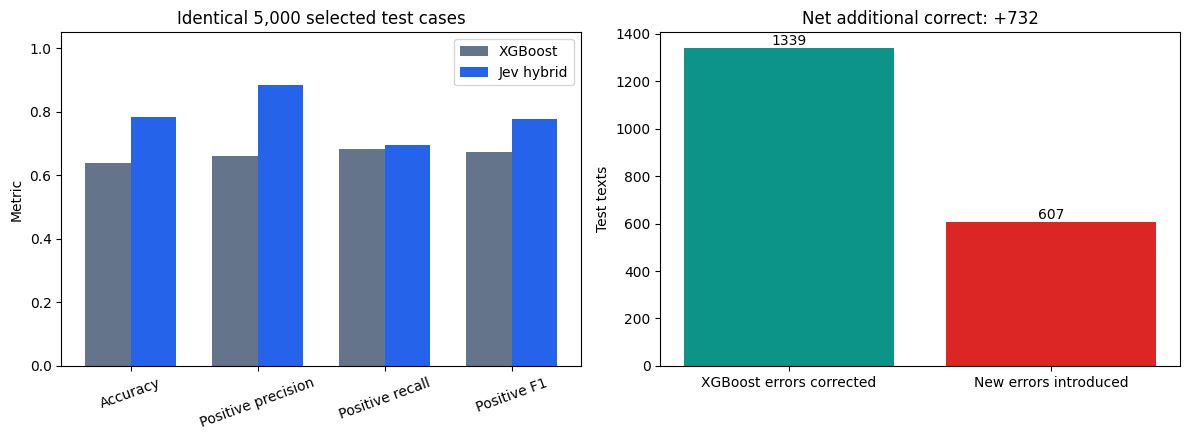

In [8]:
population = report["selected_subset"]
keys = ["accuracy", "precision_positive", "recall_positive", "f1_positive"]
labels = ["Accuracy", "Positive precision", "Positive recall", "Positive F1"]
x = np.arange(len(keys))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(x - 0.18, [population["xgboost"][key] for key in keys], width=0.36, label="XGBoost", color="#64748b")
axes[0].bar(x + 0.18, [population["hybrid"][key] for key in keys], width=0.36, label="Jev hybrid", color="#2563eb")
axes[0].set(xticks=x, xticklabels=labels, ylim=(0, 1.05), ylabel="Metric", title="Identical 5,000 selected test cases")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()
paired = population["paired"]
counts = [paired["corrected_xgboost_errors"], paired["introduced_errors"]]
axes[1].bar(["XGBoost errors corrected", "New errors introduced"], counts, color=["#0d9488", "#dc2626"])
axes[1].set(ylabel="Test texts", title=f"Net additional correct: {paired['net_additional_correct']:+d}")
for index, count in enumerate(counts):
    axes[1].text(index, count, str(count), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(ARTIFACTS / "figures/selected_hybrid_comparison.png", dpi=180)
plt.show()
plt.close(fig)

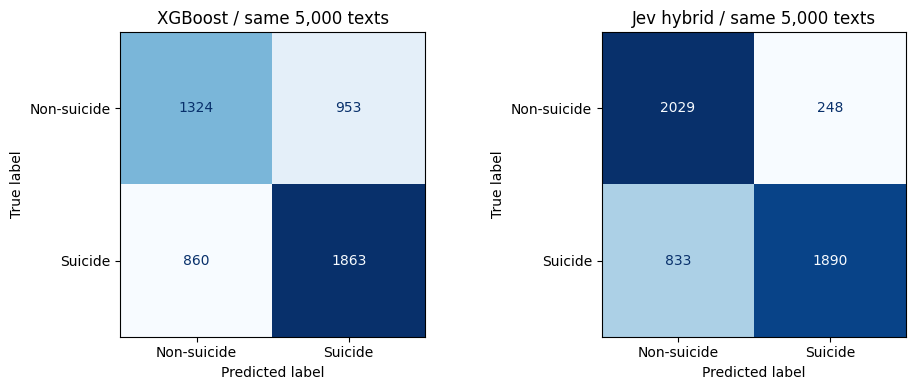

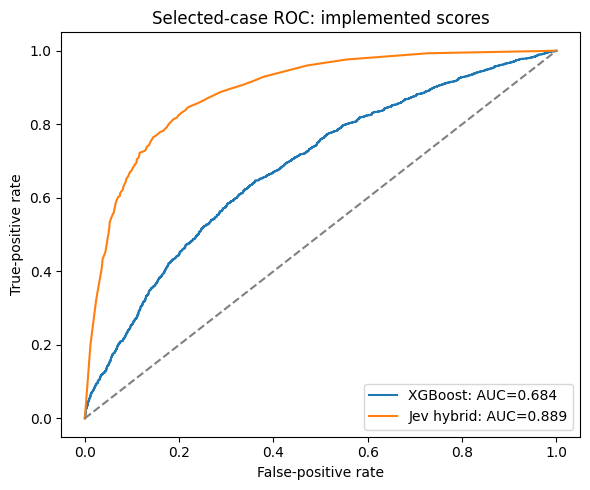

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model_key, title in zip(axes, ["xgboost", "hybrid"], ["XGBoost", "Jev hybrid"]):
    confusion = report["selected_subset"][model_key]["confusion"]
    matrix = np.array([[confusion["tn"], confusion["fp"]], [confusion["fn"], confusion["tp"]]])
    ConfusionMatrixDisplay(matrix, display_labels=["Non-suicide", "Suicide"]).plot(
        ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(title + " / same 5,000 texts")
fig.tight_layout()
fig.savefig(ARTIFACTS / "figures/selected_confusion_matrices.png", dpi=180)
plt.show()
plt.close(fig)

predictions = pd.read_json(RESULTS / "predictions.json")
assert set(predictions.sample_id) == set(manifest.sample_id)
expected = manifest.set_index("sample_id").loc[predictions.sample_id]
assert np.array_equal(predictions.y_true.to_numpy(), expected.y_true.to_numpy())
hybrid_scores = np.where(predictions.jev_status.eq("succeeded"), predictions.jev_score, predictions.p_xgb)
fig, ax = plt.subplots(figsize=(6, 5))
for scores, key, label in [(predictions.p_xgb, "xgboost", "XGBoost"),
                            (hybrid_scores, "hybrid", "Jev hybrid")]:
    auc = roc_auc_score(predictions.y_true, scores)
    assert np.isclose(auc, report["selected_subset"][key]["roc_auc"])
    fpr, tpr, _ = roc_curve(predictions.y_true, scores)
    ax.plot(fpr, tpr, label=f"{label}: AUC={auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Selected-case ROC: implemented scores")
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / "figures/selected_roc.png", dpi=180)
plt.show()
plt.close(fig)

## Interpretation limits

- The empirical validation peak and the feasible interval answer different questions. Searching 210 windows creates selection optimism on validation; the locked test comparison is the outcome evidence.
- Test labels do not select the critical interval or the routed cases. This improves on the earlier oracle-error study by measuring regressions among XGBoost-correct cases.
- This is a reused test split previously inspected by the original notebook and earlier study, so the comparison is exploratory rather than a fresh confirmatory evaluation.
- Hybrid ROC-AUC, AP, Brier score, and log loss describe piecewise XGBoost/Jev scores. Jev scores and XGBoost scores are not guaranteed to be jointly calibrated probabilities.
- `jev-latest` is a mutable provider alias without an immutable model revision. The cohort lock time and actual request window are recorded for reproducibility.
- The 5,000-attempt budget limits actual routing coverage; failed/unqueried texts stay with XGBoost. No synthetic outcomes or fine-tuned weights are presented as measured Jev results.
- Social-media labels and this study do not establish clinical validity or deployment safety.